# Welfare dynamics and network snapshots

Replay the welfare argmax from an old sweep, or manually set group size, temperature, omega, and visibility.

In [6]:
import copy
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import scienceplots  # noqa: F401
from IPython.display import display
from matplotlib_inline.backend_inline import set_matplotlib_formats
from tqdm.auto import tqdm

%matplotlib inline
plt.style.use("science")
set_matplotlib_formats("svg")
extra = 4
plt.rcParams.update({
    "font.size": 14+extra,
    "axes.titlesize": 17+extra,
    "axes.labelsize": 15+extra,
    "xtick.labelsize": 12+extra,
    "ytick.labelsize": 12+extra,
    "legend.fontsize": 12+extra,
    "legend.title_fontsize": 13+extra,
    "figure.titlesize": 19+extra,
})

project_root = next(
    (
        path
        for path in (Path.cwd().resolve(), *Path.cwd().resolve().parents)
        if (path / "pyproject.toml").is_file() and (path / "tasks").is_dir()
    ),
    None,
)
if project_root is None:
    raise RuntimeError("Run this notebook from the network-creation repository.")
if str(project_root) not in sys.path:
    sys.path.insert(0, str(project_root))

from network_creation.core.observability import ObservationSampling
from network_creation.io import read_json
from network_creation.observers.social_welfare_observer import (
    CenteredMeanWelfareObserver,
)
from network_creation.observers.state_history_observer import StateHistoryObserver
from network_creation.plotting.episode_series import plot_episode_series_observer
from network_creation.plotting.graph_history import (
    build_circle_layout,
    plot_graph_history,
)
from network_creation.time_normalization import normalized_source_times
from tasks.policies import (
    load_policy_results,
    prepare_instrumented_policy_simulation,
)

## Configuration

In [24]:
CONFIG = {
    "source_zarr": (
        project_root
        / "artifacts"
        / "simulation_runs"
        / "run-20260809T034029.zarr"
    ),
    "input_mode": "manual",  # "sweep_argmax" or "manual"
    "sweep_group_size": 100,
    "manual_parameters": {
        "n_agents": 1000,
        "temperature": 0.001,
        "omega": 0.498,
        "visibility": 7,
    },
    "objective": "centered_mean_welfare.mean",
    "visualization": {
        "seed": 13,
        "n_episodes": 32,
        "checkpoint_every": 1.0,
        "episode": 0,
        "graph_times": [0, 5, 10, 20],
    },
}

## Build the simulation input

In [25]:
def load_source_run_config(config, results=None):
    result_store = Path(config["source_zarr"])
    config_path = result_store / "run_config.json"
    if not config_path.is_file():
        if results is None:
            raise FileNotFoundError(f"Missing source run config: {config_path}")
        config_path = Path(results.attrs["config_path"])
    return read_json(config_path)


def select_best_input(config, group_size):
    result_store = Path(config["source_zarr"])
    group_size = int(group_size)
    objective = str(config["objective"])
    results = load_policy_results(
        result_store, stats=(objective,), normalize_time=False
    )
    final_step = int(
        results.coords["last_valid_raw_step"].sel(n_agents=group_size).item()
    )
    scores = results["x"].sel(
        n_agents=group_size, observable=objective, step=final_step, drop=True
    )
    values = np.asarray(scores.values, dtype=float)
    best_welfare = float(np.nanmax(values))
    positions = np.argwhere(np.isfinite(values) & (values == best_welfare))
    candidates = []
    for position in positions:
        selector = {
            dimension: scores.coords[dimension].values[int(index)].item()
            for dimension, index in zip(scores.dims, position, strict=True)
        }
        input_index = int(
            results.coords["input_index"].sel(
                {"n_agents": group_size, **selector}
            ).item()
        )
        candidates.append((input_index, selector))
    input_index, selector = min(candidates, key=lambda candidate: candidate[0])
    theta_row = results["theta"].sel(
        {"n_agents": group_size, **selector}, drop=True
    )
    theta = {
        str(name): float(value)
        for name, value in zip(
            theta_row.coords["theta_parameter"].values,
            theta_row.values,
            strict=True,
        )
    }
    return {
        "run_config": load_source_run_config(config, results),
        "group_size": group_size,
        "input_index": input_index,
        "theta": theta,
    }

In [26]:
def build_manual_input(run_config, parameters):
    run_config = copy.deepcopy(run_config)
    n_agents = int(parameters["n_agents"])
    temperature = float(parameters["temperature"])
    omega = float(parameters["omega"])
    visibility = float(parameters["visibility"])
    if not visibility.is_integer():
        raise ValueError("manual visibility must be an integer")

    population = run_config["population"]
    population["n_agents"] = n_agents
    population["visibility_distance"] = {
        "kind": "fixed",
        "value": int(visibility),
    }
    best_response_policy = next(
        policy
        for policy in population["policies"]
        if policy["id"] == "best_response"
    )
    best_response_policy["parameters"]["exploration"] = {
        "kind": "fixed",
        "value": temperature,
    }
    best_response_policy["parameters"]["outside_optimism"] = {
        "kind": "fixed",
        "value": omega,
    }

    theta = {
        "exploration": temperature,
        "outside_optimism": omega,
        "visibility_distance": visibility,
    }
    for parameter_name, spec in run_config.get("game", {}).items():
        if spec["kind"] == "fixed":
            theta[parameter_name] = float(spec["value"])
        elif spec["kind"] == "scaled_inverse_agents":
            theta[parameter_name] = float(np.float32(
                float(spec["numerator"])
                / (float(spec["factor"]) * n_agents)
            ))
        else:
            raise ValueError(
                f"Manual mode does not support game parameter kind "
                f"{spec['kind']!r}"
            )

    return {
        "run_config": run_config,
        "group_size": n_agents,
        "input_index": 0,
        "theta": theta,
    }


input_mode = str(CONFIG["input_mode"])
if input_mode == "sweep_argmax":
    selection = select_best_input(CONFIG, CONFIG["sweep_group_size"])
    simulation_input = selection
    parameter_origin = f"sweep argmax at n={selection['group_size']}"
    figure_run_name = f"sweep-argmax-n{selection['group_size']}"
elif input_mode == "manual":
    selection = None
    simulation_input = build_manual_input(
        load_source_run_config(CONFIG), CONFIG["manual_parameters"]
    )
    parameter_origin = "manual parameters"
    figure_run_name = f"manual-n{simulation_input['group_size']}"
else:
    raise ValueError(
        f"Unknown input_mode {input_mode!r}; use 'sweep_argmax' or 'manual'"
    )

n_agents = simulation_input["group_size"]
n_actors = min(
    int(simulation_input["run_config"]["simulator"]["actor_scheduler"]["n_actors"]),
    n_agents,
)
raw_checkpoint_interval = int(round(
    CONFIG["visualization"]["checkpoint_every"] * n_agents / n_actors
))
figure_output_dir = (
    project_root
    / "artifacts"
    / "figures"
    / Path(CONFIG["source_zarr"]).stem
    / figure_run_name
)
figure_output_dir.mkdir(parents=True, exist_ok=True)
input_summary = {
    "input mode": input_mode,
    "simulated n_agents": n_agents,
    "temperature (exploration)": simulation_input["theta"]["exploration"],
    "omega (outside_optimism)": simulation_input["theta"]["outside_optimism"],
    "visibility": int(simulation_input["theta"]["visibility_distance"]),
}
if selection is not None:
    input_summary["selected sweep input_index"] = selection["input_index"]
display(input_summary)


def run_selected(selected_input, options, observers, *, description):
    run_config = copy.deepcopy(selected_input["run_config"])
    run_config["simulator"]["seed"] = int(options["seed"])
    run_config["simulator"]["n_episodes"] = int(options["n_episodes"])
    prepared = prepare_instrumented_policy_simulation(
        run_config,
        input_index=selected_input["input_index"],
        observers=observers,
    )
    for episode in tqdm(
        range(prepared.settings.n_episodes),
        desc=description,
        unit="episode",
    ):
        prepared.simulator.run(
            n_episodes=1, reset_observers=(episode == 0)
        )
    return prepared

{'input mode': 'manual',
 'simulated n_agents': 1000,
 'temperature (exploration)': 0.001,
 'omega (outside_optimism)': 0.498,
 'visibility': 7}

## Welfare and graph snapshots

Visualization (n=1000, manual parameters):   0%|          | 0/32 [00:00<?, ?episode/s]

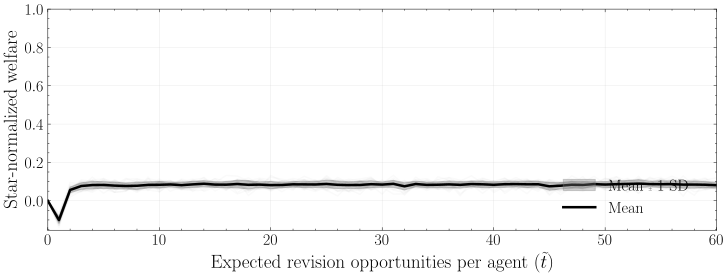

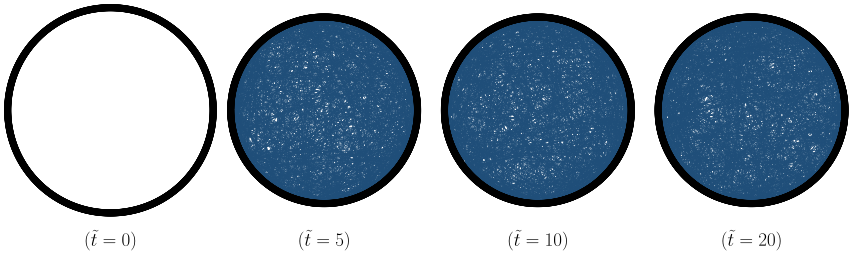

In [27]:
visualization = CONFIG["visualization"]
sampling = ObservationSampling.periodic(raw_checkpoint_interval)
welfare_observer = CenteredMeanWelfareObserver(
    n_agents=n_agents,
    observation_sampling=sampling,
    benefit_to_cost_ratio=simulation_input["theta"]["benefit_to_cost_ratio"],
    distance_discount=simulation_input["theta"]["distance_discount"],
    aggregations=("mean", "std", "runs"),
)
history_observer = StateHistoryObserver(
    observation_sampling=sampling, keep_runs=True
)
visualization_run = run_selected(
    simulation_input,
    visualization,
    (welfare_observer, history_observer),
    description=f"Visualization (n={n_agents}, {parameter_origin})",
)
welfare_times = normalized_source_times(
    welfare_observer.steps, n_agents=n_agents, n_actors=n_actors
).reshape(-1)
welfare_figure, welfare_axis = plt.subplots(figsize=(12, 4))
plot_episode_series_observer(
    observer=welfare_observer,
    ax=welfare_axis,
    show_runs=True,
    color="black",
    band_color="gray",
    set_title=False,
    x_values=welfare_times,
    x_label=r"Expected revision opportunities per agent ($\tilde t$)",
)
welfare_legend = welfare_axis.get_legend()
if welfare_legend is not None:
    welfare_legend.set_title(None)
welfare_legend.get_texts()[0].set_text("Mean ± 1 SD")
welfare_legend.get_texts()[1].set_text("Mean")
welfare_legend.set_loc("lower right")
welfare_axis.set_ylim(top=1.0)
welfare_axis.set_ylabel("Star-normalized welfare")

history = history_observer.get()
if history.runs_steps is None or history.runs_graphs is None:
    raise RuntimeError("state-history observer did not retain episode runs")
episode = int(visualization["episode"])
graph_steps = history.runs_steps[episode]
graph_times = normalized_source_times(
    graph_steps, n_agents=n_agents, n_actors=n_actors
).reshape(-1)
graph_indices = [
    int(np.abs(graph_times - time).argmin())
    for time in visualization["graph_times"]
]
snapshot_times = np.asarray(visualization["graph_times"], dtype=np.int_)
snapshots_figure, snapshot_axes = plot_graph_history(
    steps=snapshot_times,
    graphs=tuple(history.runs_graphs[episode][index] for index in graph_indices),
    layout=build_circle_layout(n_agents),
    figure_title=None,
    max_cols=len(graph_indices),
    draw_kwargs={
        "with_labels": False,
        "node_shape": "o",
        "node_size": 45,
        "node_color": "black",
        "edgecolors": "black",
        "linewidths": 0.5,
        "width": 0.8,
        "arrowsize": 7,
        "margins": 0.02,
    },
)
for axis, time in zip(snapshot_axes.ravel(), snapshot_times, strict=True):
    axis.set_title("")
    axis.text(
        0.5, -0.06, rf"$(\tilde t={time:g})$", transform=axis.transAxes,
        ha="center", va="top", fontsize=plt.rcParams["axes.labelsize"],
    )
snapshots_figure.set_size_inches(12, 4)
snapshots_figure.subplots_adjust(
    left=0.005, right=0.995, bottom=0.12, top=0.995, wspace=0.0
)
welfare_figure_path = figure_output_dir / "welfare_dynamics.pdf"
snapshots_figure_path = figure_output_dir / "network_snapshots.pdf"
welfare_figure.savefig(
    welfare_figure_path, format="pdf", bbox_inches="tight"
)
snapshots_figure.savefig(
    snapshots_figure_path, format="pdf", bbox_inches="tight"
)
display(welfare_figure)
display(snapshots_figure)
plt.close(welfare_figure)
plt.close(snapshots_figure)